In [ ]:
import pandas as pd
import glob
import os

files_list = glob.glob("/content/*.csv")

print("CSV files found:", files_list)

if files_list:
    df = pd.read_csv(files_list[0], encoding="latin1")
    print("Dataset loaded successfully!")
    print("Dataset shape:", df.shape)
    display(df.head())
else:
    print("CSV file not found. Please upload your dataset.")

CSV files found: []
CSV file not found. Please upload your dataset.


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving Sample-Superstore.csv file.xlsx to Sample-Superstore.csv file (1).xlsx


In [ ]:
import pandas as pd
import glob
import os

files_list = glob.glob("/content/*")

print("Uploaded files:")
for f in files_list:
    print(os.path.basename(f))

Uploaded files:
Sample-Superstore.csv file (1).xlsx
Sample-Superstore.csv file.xlsx
sample_data


In [ ]:
file_path = files_list[0]

if file_path.lower().endswith((".xlsx", ".xls")):
    df = pd.read_excel(file_path)
else:
    df = pd.read_csv(file_path, encoding="latin1")

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)
display(df.head())


Dataset loaded successfully!
Rows and columns: (10194, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


In [ ]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Dataset shape: (10194, 21)

Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          10194 non-null  int64         
 1   Order ID        10194 non-null  object        
 2   Order Date      10194 non-null  datetime64[ns]
 3   Ship Date       10194 non-null  datetime64[ns]
 4   Ship Mode       10194 non-null  object        
 5   Customer ID     10194 non-null  object        
 6   Customer Name   10194 non-null  object        
 7   Segment         10194 non-null  object        
 8   Country/Region  10194 non-

In [ ]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country/Region    0
City              0
State/Province    0
Postal Code       0
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
dtype: int64


In [ ]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [ ]:
display(df.describe().T)

,count,mean,min,25%,50%,75%,max,std
Row ID,10194.0,5097.5,1.0,2549.25,5097.5,7645.75,10194.0,2942.898656
Order Date,10194,2025-04-29 11:48:25.002942720,2023-01-03 00:00:00,2024-05-14 00:00:00,2025-06-25 00:00:00,2026-05-14 00:00:00,2026-12-30 00:00:00,NaN
Ship Date,10194,2025-05-03 10:52:45.626839296,2023-01-07 00:00:00,2024-05-19 00:00:00,2025-06-28 00:00:00,2026-05-18 00:00:00,2027-01-05 00:00:00,NaN
Sales,10194.0,228.225854,0.444,17.22,53.91,209.5,22638.48,619.906839
Quantity,10194.0,3.791838,1.0,2.0,3.0,5.0,14.0,2.228317
Discount,10194.0,0.155385,0.0,0.0,0.2,0.2,0.8,0.206249
Profit,10194.0,28.673417,-6599.978,1.7608,8.69,29.297925,8399.976,232.465115


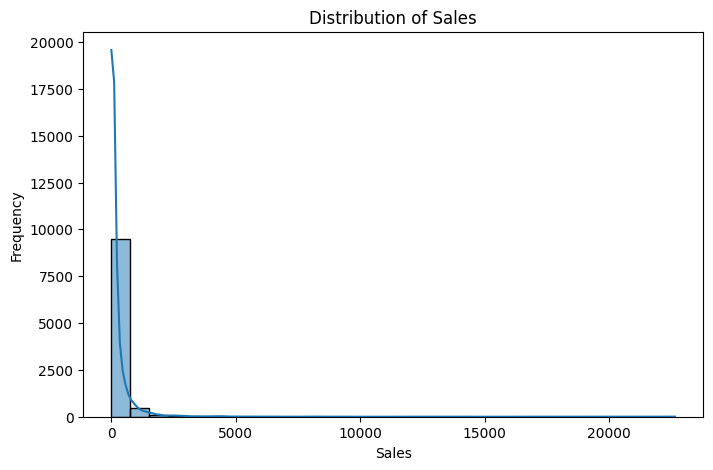

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Sales", bins=30, kde=True)
plt.title("Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.show()


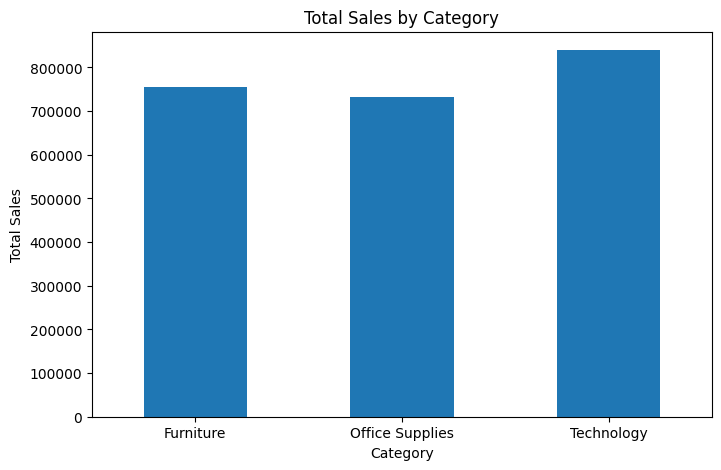

In [ ]:
category_sales = df.groupby("Category")["Sales"].sum()

category_sales.plot(kind="bar", figsize=(8, 5))
plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.show()


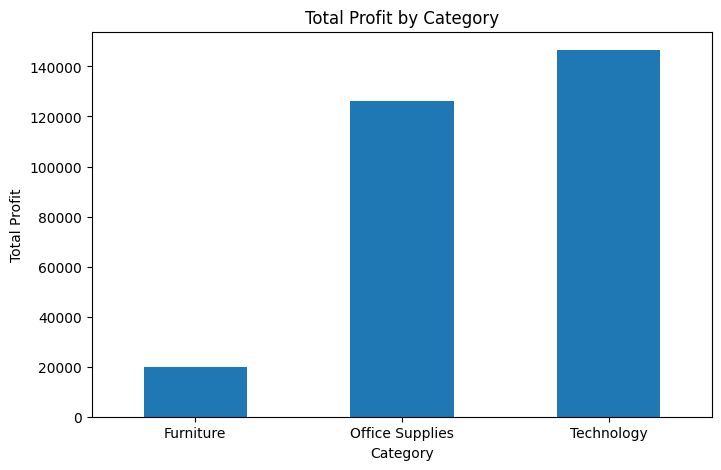

In [ ]:
category_profit = df.groupby("Category")["Profit"].sum()

category_profit.plot(kind="bar", figsize=(8, 5))
plt.title("Total Profit by Category")
plt.xlabel("Category")
plt.ylabel("Total Profit")
plt.xticks(rotation=0)
plt.show()


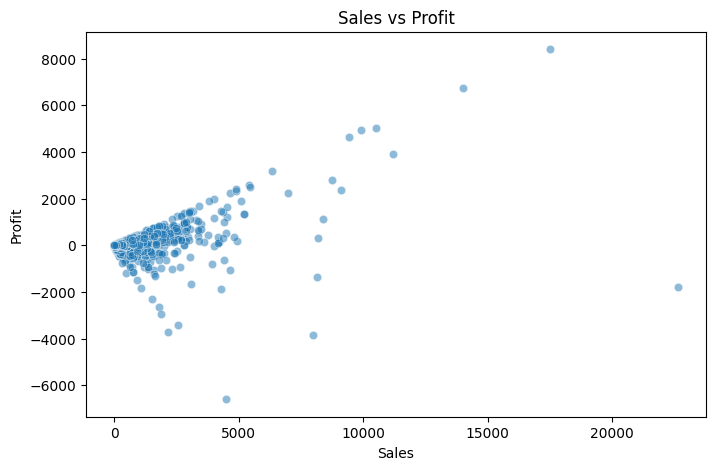

In [ ]:

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Sales", y="Profit", alpha=0.5)
plt.title("Sales vs Profit")
plt.show()


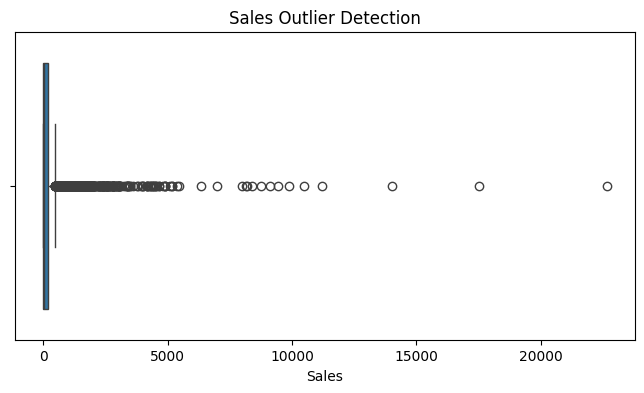

In [ ]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["Sales"])
plt.title("Sales Outlier Detection")
plt.show()

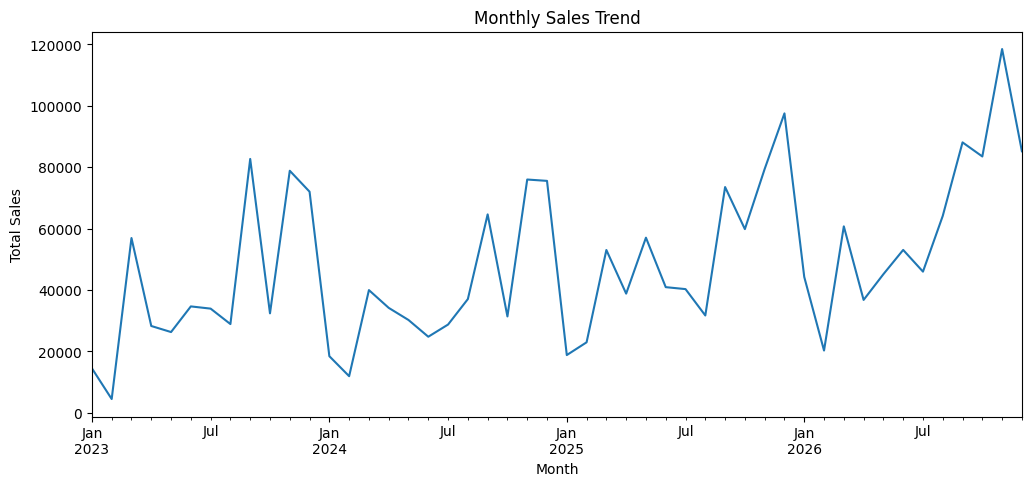

In [ ]:

df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")

monthly_sales = (
    df.dropna(subset=["Order Date"])
      .set_index("Order Date")
      .resample("MS")["Sales"]
      .sum()
)

monthly_sales.plot(figsize=(12, 5))
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.show()


Top 3 Insights

1. Sales Performance: The product category with the highest total sales was __________.

2. Profitability: The product category with the highest total profit was __________.

3. Monthly Sales Trend: Monthly sales fluctuated over time, with noticeable peaks and declines.

Conclusion

Exploratory Data Analysis was performed on the Sample Superstore dataset using Python. The analysis examined sales distribution, category-wise sales and profit, the relationship between sales and profit, potential outliers, and monthly sales trends. These findings help understand business performance and support data-driven decision-making.